# Step 9: grade the burn maps, and try two fixes for the leaf season

**Goal:** measure how good the Step 8 burn maps are, and test whether comparing each pixel with "normal" unburned land rescues the April map.

**Answer key:** the official fire outline. A pixel inside it counts as really burned.

Two grades per map, the same as for the flood maps:
- **Caught:** the share of the outline the map flagged.
- **Right:** the share of the map's flags that fall inside the outline.

**The problem from Step 8:** between March 11 and April 12 the whole landscape greened up, so "no change" is no longer at zero.

**Two fixes.** Both ask: *did this pixel's score fall 0.10 more than normal?* They differ in what "normal" means.
- **Fix A, look-alikes:** normal = the typical change of pixels that had a similar burn score before the fire, anywhere in the box. It never uses the outline.
- **Fix B, ring:** normal = the typical change in a ring of land 300 m to 2 km outside the outline. This is what the national burn archive does. It uses the answer key to build the map.

These rules were written down before any score was computed.

In [1]:
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import numpy as np
import pandas as pd
import hls, fires
step9 = importlib.import_module('09_grade_burn_maps')  # reuse the script's functions
# The script saves pictures to files only. This line also shows them here in the notebook.
%matplotlib inline
hls.login();

## Build all eight maps
Two pairs of photos, four maps each: the two plain maps from Step 8 (textbook cutoff, histogram cutoff) and the two fixes.

In [2]:
r = step9.run()
inside, ring = r['inside'], r['ring']
print(f"Outline: {inside.sum() * step9.KM2:.1f} km2 = {inside.mean():.0%} of the box. Ring: {ring.sum() * step9.KM2:.1f} km2.")
for pair, d in r['data'].items():
    print(f"{pair} pair: can see {d['usable'][inside].mean():.0%} of the outline")

Outline: 31.1 km2 = 10% of the box. Ring: 86.3 km2.
April pair: can see 89% of the outline
March 26 pair: can see 100% of the outline


## What "normal change" looks like
Each dot is one look-alike group (5% of the box). Left = pixels that were bare or leafless before the fire. Right = evergreen. The dashed line is the single number the ring gives.

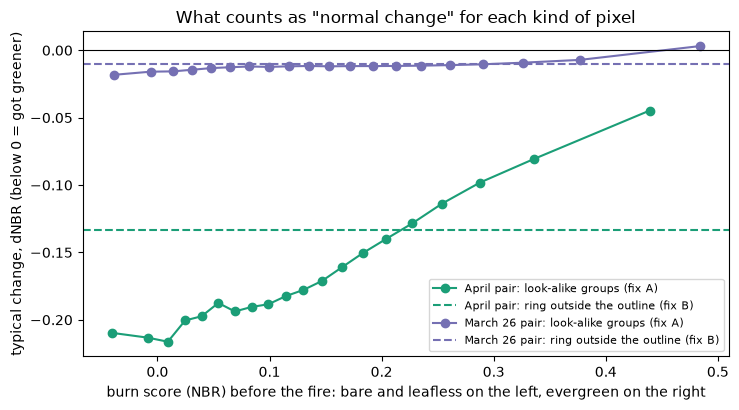

In [3]:
step9.plot_normal(r['groups'], r['ring_normal'], '../figures/09_normal_change.png');

- **March 26 pair (purple):** flat, close to zero. In 8 days nothing changed, so there is nothing to fix.
- **April pair (green):** leafless pixels greened up by about 0.2, evergreens by only 0.05. One number for the whole box (the dashed line) fits neither end.

## The grades

In [4]:
r['scores']

,pair,map,flagged km2,caught,right,F1,false alarms km2,overall accuracy
0,April,say nothing burned (baseline),0.0,0.000,NaN,0.000,0.0,0.890
1,April,textbook,4.4,0.157,0.993,0.272,0.0,0.907
2,April,histogram,7.7,0.262,0.939,0.409,0.5,0.917
3,April,fix A: look-alikes,45.3,0.422,0.257,0.320,33.6,0.803
4,April,fix B: ring,31.0,0.366,0.325,0.344,21.0,0.847
5,March 26,say nothing burned (baseline),0.0,0.000,NaN,0.000,0.0,0.902
6,March 26,textbook,19.8,0.613,0.958,0.747,0.8,0.959
7,March 26,histogram,26.9,0.728,0.839,0.779,4.3,0.960
8,March 26,fix A: look-alikes,21.2,0.646,0.944,0.767,1.2,0.962
9,March 26,fix B: ring,21.0,0.641,0.945,0.764,1.1,0.961


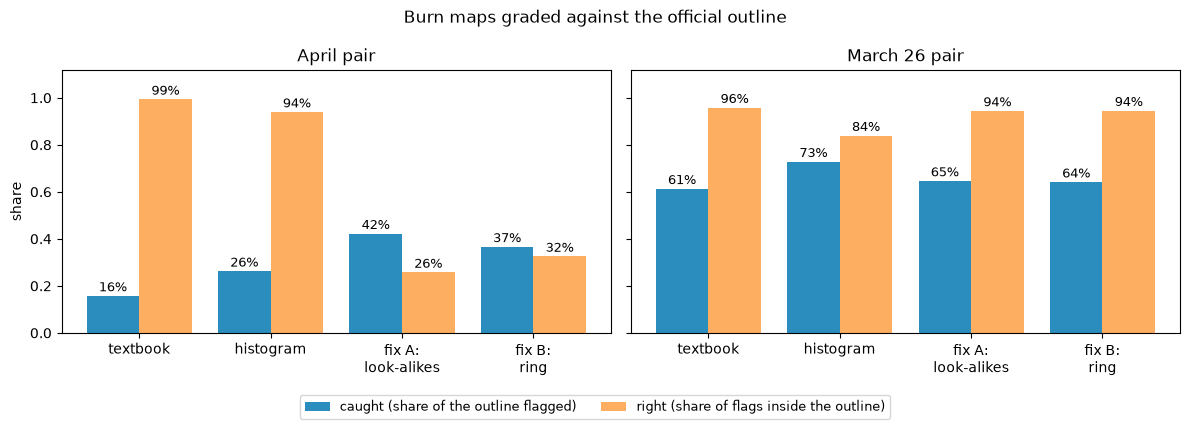

In [5]:
step9.plot_scores(r['scores'], '../figures/09_burn_scores.png');

**Overall accuracy is useless again.** Only 10% of the box burned, so "say nothing burned" already scores about 90%.

## Where each map is right and wrong

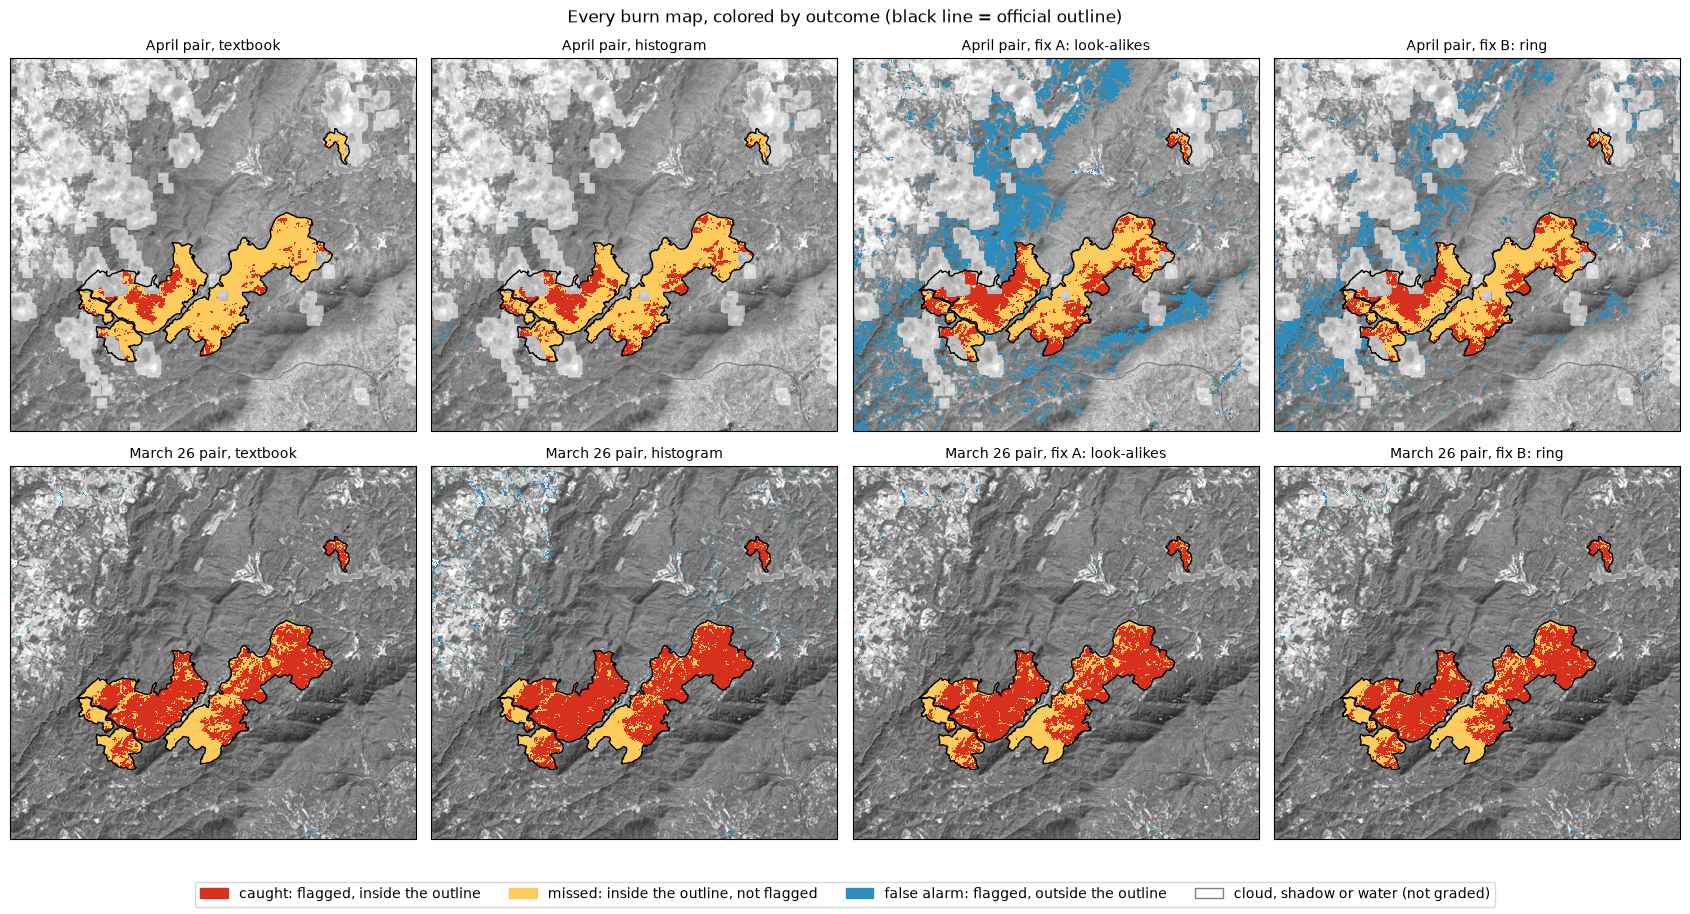

In [6]:
step9.plot_outcomes(r['maps'], r['data'], inside, '../figures/09_burn_map_outcomes.png');

## What we learned
- **Both fixes failed on the April pair.** They catch more of the burn (26% up to 42% and 37%), but most of their flags are wrong (right falls from 94% to 26% and 32%). The plain histogram map is still the best April map on balance.
- **Where the false alarms are:** big patches along the mountain ridges next to the burn. Likely reason (not proven): higher ground greens up later in spring, so on April 12 the ridges had not leafed out yet. To a "greened up less than normal" rule, that looks like a burn. I did not load height data, so this is a guess to test.
- **Fix A did not beat fix B.** Grouping by the before-fire score separates fields from pines, but it cannot tell a ridge from a valley.
- **On the March 26 pair the fixes change almost nothing,** because unburned land barely moved in 8 days.
- **Best map overall: March 26, histogram cutoff.** Caught 73%, right 84%.
- **Timing beat method.** A photo taken days after the fire, before the leaves came out, gave a far better map than any correction applied to a later photo.

## Limits of this grading
- **The outline is not perfect truth.** Patches inside a fire outline often did not burn, so 100% caught is not possible. The outline is also marked "auto-generated", not "certified".
- **The March 26 grade is unfair to that map.** The fire grew until about March 31. Ground that burned after March 26 counts as "missed".
- **The April pair cannot see 11% of the outline** (cloud). Those pixels are not graded.
- **Fix B is not independent of the answer key.** It uses the outline to choose its ring.